In [169]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import os, glob
import pandas as pd

In [170]:
import matplotlib as mpl
import matplotlib.font_manager as fm

FONT_DIR = os.path.expanduser("~/fonts/SourceSans3")

for f in glob.glob(os.path.join(FONT_DIR, "*.ttf")):
    fm.fontManager.addfont(f)

available = {f.name for f in fm.fontManager.ttflist}
FAMILY = next((n for n in ("Source Sans 3", "Source Sans Pro") if n in available), None)
if FAMILY is None:
    raise RuntimeError(f"Source Sans not found. Check FONT_DIR: {FONT_DIR}")

W = 418.25372 / 72.27   # \textwidth in inches (~5.787)
W_HALF = 0.48 * W       # two panels side by side

mpl.rcParams.update({
    # --- Text / fonts ---
    "text.usetex": False,
    "font.family": "sans-serif",
    "font.sans-serif": [FAMILY],
    "mathtext.fontset": "custom",
    "mathtext.rm": FAMILY,
    "mathtext.it": f"{FAMILY}:italic",
    "mathtext.bf": f"{FAMILY}:bold",
    "mathtext.sf": FAMILY,
    "mathtext.default": "it",
    "mathtext.fallback": "cm",     
    "axes.unicode_minus": True,    

    "font.size": 10,
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.titlesize": 10,

    "axes.linewidth": 0.8,
    "lines.linewidth": 1.3,
    "lines.markersize": 4,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 3.5,
    "ytick.major.size": 3.5,
    "xtick.minor.width": 0.6,
    "ytick.minor.width": 0.6,
    "xtick.minor.size": 2,
    "ytick.minor.size": 2,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "grid.linewidth": 0.5,
    "grid.alpha": 0.4,

    "legend.frameon": False,
    "legend.handlelength": 1.5,

    "figure.figsize": (W, W),
    "figure.constrained_layout.use": True,
    "savefig.dpi": 300,             
    "savefig.format": "pdf",
    "pdf.fonttype": 42,    
    "ps.fonttype": 42,
    "svg.fonttype": "none",
})

In [171]:
run = '2024/oper_08'
reference_years = np.arange(1991, 2006, 1)
release = 2

In [172]:
path = '/jetfs/scratch/psplechtna/thesisdata/oper/'

In [173]:
data = xr.open_dataset(path+run+'_temporal_evol.nc')
data_tsr = xr.open_dataset(path+run+'_tsr.nc')
reference = xr.open_mfdataset([path+f'1991-2020/{year}_temporal_evol.nc' for year in reference_years])
ref_tsr = xr.open_mfdataset([path+f'1991-2020/{year}_tsr.nc' for year in reference_years])

In [174]:
reference_mean = reference.mean(dim='release_time')
reference_std = reference.std(dim='release_time')

In [175]:
data = data.isel(release_time=release)
data_tsr = data_tsr.isel(release_date=release)

In [176]:
t_release=pd.Timestamp(data.release_time.values)

In [177]:
data['tot_anom'] = data.flux_lh + data.flux_sh + data.advection + data.rad_sw + data.rad_lw + data.seasonality + data_tsr.init_anomaly

findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive
findfont: Failed to find font weight bold for Source Sans 3, now using 400.


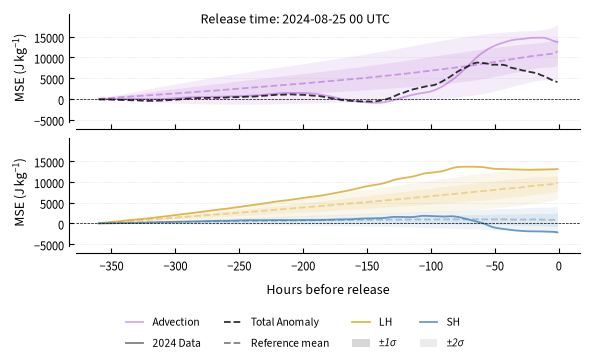

In [178]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

def plot_var(ax, name, color, label, alpha=0.8):
    m, s = reference_mean[name], reference_std[name]
    ax.plot(xes, data[name], color=color, ls='-', alpha=alpha, label=label)
    ax.plot(xes, m, color=color, ls='--', alpha=0.4)
    for n, a in [(1, 0.1), (2, 0.09)]:
        ax.fill_between(xes, m - n*s, m + n*s, color=color, alpha=a, linewidth=0)

xes = data.lag
fig, ax = plt.subplots(2, 1, figsize=(W, 0.6*W), sharex=True)

plot_var(ax[0], 'advection', 'darkorchid', 'Advection', alpha=0.4)
plot_var(ax[1], 'flux_lh', 'goldenrod', 'LH')
plot_var(ax[1], 'flux_sh', 'steelblue', 'SH')

ax[0].plot(xes, data.tot_anom, color='k', linestyle='--', alpha=0.8, label='Total Anomaly')

# one entry per color (collected from both axes)
handles, labels = [], []
for a in ax:
    h, l = a.get_legend_handles_labels()
    handles += h; labels += l
    a.grid(ls=':', alpha=0.5, axis='y')
    a.axhline(0, color='k', ls='--', lw=0.5)
    a.set_ylim(-5500, 20500)
    a.set_yticks(np.arange(-5000, 20000, 5000))
    a.set_ylabel(r'MSE ($\mathrm{J\,kg^{-1}}$)')
    for spine in ['top', 'right']:
        a.spines[spine].set_visible(False)
    spine_offset = 5
    a.spines.left.set_position(('outward', spine_offset))
    a.spines.bottom.set_position(('outward', spine_offset))

ax[1].set_xlabel('Hours before release')

# one entry per style, in neutral gray
style_handles = [
    Line2D([], [], color='gray', ls='-',  label='2024 Data'),
    Line2D([], [], color='gray', ls='--', label='Reference mean'),
    Patch(facecolor='gray', alpha=0.30, label=r'$\pm 1\sigma$'),
    Patch(facecolor='gray', alpha=0.15, label=r'$\pm 2\sigma$'),
]
all_handles = handles + style_handles
ncol = 4
reordered = [h for i in range(ncol) for h in all_handles[i::ncol]]

fig.suptitle(f'Release time: {t_release:%Y-%m-%d %H} UTC', y=1)
fig.legend(handles=reordered, ncol=ncol, fontsize='small',
             loc='outside lower center')
#fig.savefig('plots/temporal_evol.pdf')

## variance decomposition

In [179]:
terms_t = ["flux_lh", "flux_sh", "advection",
           "seasonality"]

ref = reference.drop_vars(["expver", "number"], errors="ignore").sortby("lag")

# align the two datasets (release_time vs release_date)
assert (ref["release_time"].values == ref_tsr["release_date"].values).all(), "release times differ"
D    = ref_tsr["diag_anomaly"].values.astype(float)
init = ref_tsr["init_anomaly"].values.astype(float)
years = pd.DatetimeIndex(ref["release_time"].values).year.values

C = np.stack([ref[v].values for v in terms_t], axis=-1).astype(float)   # (n, 360, 4), cumulative from t0
assert not np.isnan(C).any(), "NaNs in terms: decide how to handle them"
lag_d = ref["lag"].values / 24                                          # -15 ... ~0 days

# consistency with the scalar totals (cumulative value at lag = -1)
for k, v in enumerate(terms_t):
    tot = ref_tsr[v].values.astype(float)
    print(f"{v:12s} max|C(lag=-1) - total| = {np.abs(C[:, -1, k] - tot).max():.3g}"
          f"   (std of total = {tot.std():.3g})")

def transform(x, yrs, mode):
    uy = np.unique(yrs)
    if mode == "pooled":
        return x
    if mode == "between":                      # one value per summer
        return np.stack([x[yrs == y].mean(0) for y in uy])
    x = x.astype(float).copy()                 # "within": deviations from each summer's own mean
    for y in uy:
        x[yrs == y] -= x[yrs == y].mean(0)
    return x

def decomp(C, D, init, yrs, mode="pooled"):
    Cm, Dm, Im = (transform(a, yrs, mode) for a in (C, D, init))
    rem = Dm[:, None] - Im[:, None] - Cm.sum(-1)           # (n, lag)
    Dc = Dm - Dm.mean()
    ddof = len(Dc) - 1
    var = Dc @ Dc / ddof
    beta      = np.einsum("n,ntk->tk", Dc, Cm - Cm.mean(0)) / ddof / var
    beta_rem  = (Dc @ (rem - rem.mean(0))) / ddof / var
    beta_init = (Dc @ (Im - Im.mean())) / ddof / var
    return beta, beta_rem, beta_init

def year_bootstrap(C, D, init, yrs, mode, nboot=2000, seed=0):
    rng = np.random.default_rng(seed)
    uy = np.unique(yrs)
    groups = {y: np.where(yrs == y)[0] for y in uy}
    out = []
    for _ in range(nboot):
        ys = rng.choice(uy, len(uy), replace=True)
        idx = np.concatenate([groups[y] for y in ys])
        lab = np.concatenate([np.full(len(groups[y]), i) for i, y in enumerate(ys)])
        b, br, _ = decomp(C[idx], D[idx], init[idx], lab, mode)
        out.append(np.concatenate([b, br[:, None]], axis=1))
    return np.percentile(out, [2.5, 97.5], axis=0)         # (2, lag, k+1)

mode = 'within'                                            # "pooled" | "between" | "within"
beta, beta_rem, beta_init = decomp(C, D, init, years, mode)
names = terms_t + ['remainder (to come + rad + resid)']
B = np.concatenate([beta, beta_rem[:, None]], axis=1)
print(f'beta_init = {beta_init:.2f}; sum at lag=-1: {B[-1].sum() + beta_init:.3f} (should be 1)')
ci = year_bootstrap(C, D, init, years, mode) if len(np.unique(years)) >= 10 else None
for v in range(len(names)):
    print(f'{names[v]}: {B[-1][v]}, ci: {ci[0][-1][v]}, {ci[1][-1][v]}')

flux_lh      max|C(lag=-1) - total| = 0   (std of total = 1.88e+03)
flux_sh      max|C(lag=-1) - total| = 0   (std of total = 1.66e+03)
advection    max|C(lag=-1) - total| = 0   (std of total = 3.24e+03)
seasonality  max|C(lag=-1) - total| = 0   (std of total = 2.56e+03)
beta_init = 0.05; sum at lag=-1: 1.000 (should be 1)
flux_lh: 0.3792514896394392, ci: 0.2874798846299417, 0.4746809683949101
flux_sh: -0.13118491084986733, ci: -0.20031253955800363, -0.05653102229129402
advection: 0.8680734856625946, ci: 0.7758234981449807, 0.9572129240563505
seasonality: -0.05538115482239236, ci: -0.18887797133301845, 0.09742148576656443
remainder (to come + rad + resid): -0.11406818420861413, ci: -0.21668006094998626, -0.017959846913022836


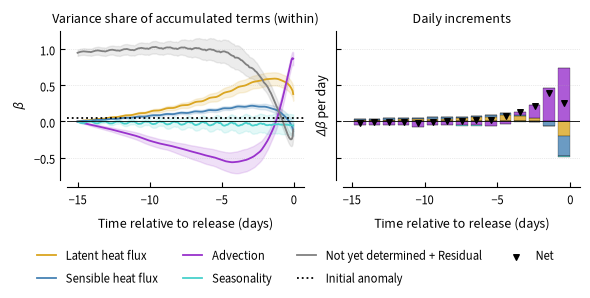

In [180]:
labels = {
    'seasonality':  'Seasonality',
    'advection':    'Advection',
    'flux_lh':      'Latent heat flux',
    'flux_sh':      'Sensible heat flux',
    'remainder (to come + rad + resid)': 'Not yet determined + Residual'
}

colors = {
    "flux_lh":    "goldenrod",
    "flux_sh":    "steelblue",
    "advection":  "darkorchid",
    "remainder (to come + rad + resid)": "grey",
    "seasonality":"mediumturquoise",
}

fig, ax = plt.subplots(1, 2, figsize=(W, 0.5*W), sharey=True)

# (a) beta vs. lag
for k, n in enumerate(names):
    ax[0].plot(lag_d, B[:, k], label=labels[n], color=colors[n])
    if ci is not None:
        ax[0].fill_between(lag_d, ci[0, :, k], ci[1, :, k], alpha=.15, color=colors[n])
ax[0].axhline(beta_init, color="k", ls=":", label="Initial anomaly")
ax[0].axhline(0, color="k", lw=.6)
ax[0].set_xlabel("Time relative to release (days)")
ax[0].set_ylabel(r"$\beta$")
ax[0].set_title(f"Variance share of accumulated terms ({mode})")

# (b) daily increments of beta (stacked)
spd = 24
inc = (B[spd - 1::spd] - np.vstack([np.zeros((1, B.shape[1])), B[spd - 1::spd][:-1]]))[:, :len(terms_t)]
days = lag_d[spd - 1::spd]

pos_base = np.zeros(len(days))
neg_base = np.zeros(len(days))
for k, n in enumerate(terms_t):
    v = inc[:, k]
    pos = np.where(v > 0, v, 0.0)
    neg = np.where(v < 0, v, 0.0)
    ax[1].bar(days, pos, width=-0.8, bottom=pos_base, color=colors[n], align='edge', alpha=0.8, edgecolor='k', linewidth=0.2)
    ax[1].bar(days, neg, width=-0.8, bottom=neg_base, color=colors[n], align='edge', alpha=0.8, edgecolor='k', linewidth=0.2)
    pos_base += pos
    neg_base += neg

# optional: net increment (sum of terms) as markers
ax[1].scatter(days-0.4, inc.sum(1), marker='v', color='k', label="Net")

ax[1].axhline(0, color="k", lw=.6)
ax[1].set_xlabel("Time relative to release (days)")
ax[1].set_ylabel(r"$\Delta\beta$ per day")
ax[1].set_title("Daily increments")

for axs in ax:
    for spine in ['top', 'right']:
        axs.spines[spine].set_visible(False)
    spine_offset = 5
    axs.spines.left.set_position(('outward', spine_offset))
    axs.spines.bottom.set_position(('outward', spine_offset))
    axs.grid(linestyle=':', alpha=0.5, axis='y')

fig.legend(loc='outside lower center', ncol=4)
#fig.savefig('/jetfs/home/psplechtna/plots/covariance.pdf')

beta from D column: [ 0.053  0.379 -0.131  0.868 -0.055 -0.114] | sum: 1.0 (should be 1)
row sums of 6x6 block: [ 0.053  0.379 -0.131  0.868 -0.055 -0.114] (should equal the D column)


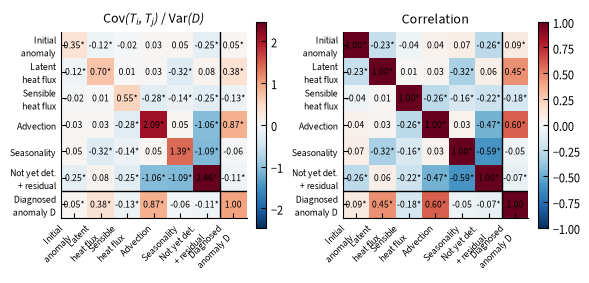

In [181]:
cols = ["init", "flux_lh", "flux_sh", "advection", "seasonality", "remainder", "D"]
lab7 = lab6 + ["Diagnosed\nanomaly D"]
K = 7

def term_matrix(C, D, init):
    T = np.column_stack([init, C[:, -1, :], D - init - C[:, -1, :].sum(1)])   # (n, 6), sums to D
    return np.column_stack([T, D])     

def cov_matrix(T, D, yrs, mode):
    Tm, Dm = transform(T, yrs, mode), transform(D, yrs, mode)
    Tc, Dc = Tm - Tm.mean(0), Dm - Dm.mean()
    n = len(Dc)
    M = Tc.T @ Tc / (n - 1) / (Dc @ Dc / (n - 1))          # Cov(Ti,Tj)/Var(D)
    s = np.sqrt(np.diag(M))
    return M, M / np.outer(s, s)                           # covariance share, correlation

T = term_matrix(C, D, init)
M, R = cov_matrix(T, D, years, mode)
print("beta from D column:", M[:6, 6].round(3), "| sum:", M[:6, 6].sum().round(3), "(should be 1)")
print("row sums of 6x6 block:", M[:6, :6].sum(1).round(3), "(should equal the D column)")
# year bootstrap
rng = np.random.default_rng(0)
uy = np.unique(years); groups = {y: np.where(years == y)[0] for y in uy}
Mb, Rb = [], []
for _ in range(2000):
    ys = rng.choice(uy, len(uy), replace=True)
    idx = np.concatenate([groups[y] for y in ys])
    lab = np.concatenate([np.full(len(groups[y]), i) for i, y in enumerate(ys)])
    m, r = cov_matrix(T[idx], D[idx], lab, mode)
    Mb.append(m); Rb.append(r)
Mlo, Mhi = np.percentile(Mb, [2.5, 97.5], axis=0)
Rlo, Rhi = np.percentile(Rb, [2.5, 97.5], axis=0)

fig, ax = plt.subplots(1, 2, figsize=(W, 0.5*W), constrained_layout=True)
lim_M = np.abs(M[:6, :]).max()                      # D,D = 1 would dominate the colour scale
for a, A, lo, hi, ttl, lim in [(ax[0], M, Mlo, Mhi, r"Cov$(T_i,T_j)$ / Var$(D)$", lim_M),
                               (ax[1], R, Rlo, Rhi, "Correlation", 1)]:
    im = a.imshow(A, cmap="RdBu_r", norm=TwoSlopeNorm(0, -lim, lim))
    for i in range(K):
        for j in range(K):
            sig = ((lo[i, j] > 0) or (hi[i, j] < 0)) and not (i == 6 and j == 6)
            a.text(j, i, f"{A[i, j]:.2f}" + ("*" if sig else ""), ha="center", va="center", fontsize=7)
    a.axhline(5.5, color="k", lw=1); a.axvline(5.5, color="k", lw=1)   # separate D from the terms
    a.set_xticks(range(K)); a.set_xticklabels(lab7, rotation=45, ha="right", fontsize=7)
    a.set_yticks(range(K)); a.set_yticklabels(lab7, fontsize=7)
    a.set_title(ttl); plt.colorbar(im, ax=a, shrink=.8)
#fig.suptitle(f"Term covariances at release ({mode}); * = 95 % year-bootstrap CI excludes 0", fontsize=8)
#fig.savefig('/jetfs/home/psplechtna/plots/heatmap.pdf')

advection     scatter beta = 0.8681 [0.7758, 0.9572] | decomposition = 0.8681
flux_lh       scatter beta = 0.3793 [0.2875, 0.4747] | decomposition = 0.3793
flux_sh       scatter beta = -0.1312 [-0.2003, -0.0565] | decomposition = -0.1312
init_anomaly  scatter beta = 0.0533 [0.0115, 0.0954] | decomposition = 0.0533


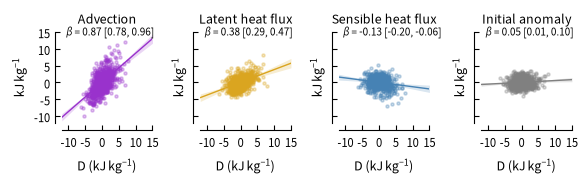

In [240]:
mode = "within"

series = {
    "advection":    C[:, -1, terms_t.index("advection")],
    "flux_lh":      C[:, -1, terms_t.index("flux_lh")],
    "flux_sh":      C[:, -1, terms_t.index("flux_sh")],
    "init_anomaly": init,
}
style = {"advection": ("Advection", "darkorchid"), "flux_lh": ("Latent heat flux", "goldenrod"),
         "flux_sh": ("Sensible heat flux", "steelblue"), "init_anomaly": ("Initial anomaly", "grey")}

def slope(x, y):
    xc, yc = x - x.mean(), y - y.mean()
    return (xc @ yc) / (xc @ xc)                       # = Cov(T, D) / Var(D)

# --- year bootstrap of the slopes (same resampling as year_bootstrap) ---
nboot = 2000
rng = np.random.default_rng(0)
uy = np.unique(years)
groups = {y: np.where(years == y)[0] for y in uy}
boot = {v: [] for v in series}
for _ in range(nboot):
    ys = rng.choice(uy, len(uy), replace=True)
    idx = np.concatenate([groups[y] for y in ys])
    lab = np.concatenate([np.full(len(groups[y]), i) for i, y in enumerate(ys)])
    xb = transform(D[idx], lab, mode)
    for v, s in series.items():
        boot[v].append(slope(xb, transform(s[idx], lab, mode)))
ci_beta = {v: np.percentile(b, [2.5, 97.5]) for v, b in boot.items()}

# --- plot ---
xD = transform(D, years, mode)
ref_beta = dict(zip(terms_t, B[-1][:4])); ref_beta["init_anomaly"] = beta_init

fig, ax = plt.subplots(1, 4, figsize=(W, 0.3*W), sharex=True, sharey=True, constrained_layout=True)
lim = (-12000, 15000)
ticks = np.arange(-10000, 15001, 5000)
ticklabels = [str(int(ticks[i]/1000)) for i in range(len(ticks))]

for a, (var, (ylab, col)) in zip(ax.flatten(), style.items()):
    y = transform(series[var], years, mode)
    a.scatter(xD, y, color=col, alpha=0.3, s=5)
    b = slope(xD, y)
    lo, hi = ci_beta[var]
    print(f"{var:13s} scatter beta = {b:.4f} [{lo:.4f}, {hi:.4f}] | decomposition = {ref_beta[var]:.4f}")
    a.text(0.05, 0.95, rf"$\beta$ = {b:.2f} [{lo:.2f}, {hi:.2f}]", transform=a.transAxes, fontsize=8)
    a.set_xlim(lim); a.set_ylim(lim) 
    a.set_xticks(ticks, ticklabels)
    a.set_yticks(ticks, ticklabels)
    a.set_aspect("equal", adjustable="box")
    a.set_xlabel(r'D ($\mathrm{kJ\,kg^{-1}}$)') 
    a.set_ylabel(r'$\mathrm{kJ\,kg^{-1}}$')
    a.set_title(f"{ylab}")
    a.spines.bottom.set_position(("outward", 5)) 
    a.spines.left.set_position(("outward", 5))
    #a.axhline(0, xmin=0.05, xmax=0.95, color="k", lw=0.7)
    #a.axvline(0, ymin=0.05, ymax=0.85, color="k", lw=0.7)
    #a.plot(lim, lim, color="k", ls="-.", lw=0.6)
    xx = np.array(lim)
    b = slope(xD, transform(series[var], years, mode))
    lo, hi = ci_beta[var]
    a.fill_between(xx, lo * xx, hi * xx, color=col, alpha=0.2, lw=0, zorder=2) 
    a.plot(xx, b * xx, color=col, lw=1, zorder=3)

    #fig.savefig('/jetfs/home/psplechtna/plots/scatter.pdf')